# Qiskit Fall Fest 2026 - Vishnu Institute of Technology
## Challenge 2: Make the Quantum Coin Biased

An H gate creates an equal superposition (a fair 50/50 quantum coin). In this challenge, we use an $R_y$ rotation gate to tilt the state and create an unequal, biased measurement distribution.

In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import numpy as np
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100

### Think Before You Run (Predictions)

A single-qubit state can be rotated using $R_y(\theta)$:
$$|\psi\rangle = \cos(\theta/2)|0\rangle + \sin(\theta/2)|1\rangle$$

- **Circuit 1 (Biased towards 0):** By choosing $\theta = \pi/3$ ($60^\circ$):
  - $P(0) = \cos^2(30^\circ) = 0.75$ (75%)
  - $P(1) = \sin^2(30^\circ) = 0.25$ (25%)
  - Prediction: 0 will occur much more frequently (~75 times out of 100).

- **Circuit 2 (Bonus - Biased towards 1):** By choosing $\theta = 2\pi/3$ ($120^\circ$):
  - $P(0) = \cos^2(60^\circ) = 0.25$ (25%)
  - $P(1) = \sin^2(60^\circ) = 0.75$ (75%)
  - Prediction: 1 will occur much more frequently (~75 times out of 100).

In [2]:
# Circuit 1: 0 occurs more frequently
qc_zero = QuantumCircuit(1, 1)
qc_zero.ry(np.pi / 3, 0)   # Ry rotation gate (1 gate <= 4 limit)
qc_zero.measure(0, 0)

print(qc_zero.draw('text'))

counts_zero = simulator.run(qc_zero, shots=shots).result().get_counts()
print("\nCounts (100 shots):", counts_zero)

     ┌─────────┐┌─┐
  q: ┤ Ry(π/3) ├┤M├
     └─────────┘└╥┘
c: 1/════════════╩═
                 0 

Counts (100 shots): {'0': 71, '1': 29}


In [3]:
# Circuit 2 (Bonus): 1 occurs more frequently
qc_one = QuantumCircuit(1, 1)
qc_one.ry(2 * np.pi / 3, 0) # Ry rotation gate
qc_one.measure(0, 0)

print(qc_one.draw('text'))

counts_one = simulator.run(qc_one, shots=shots).result().get_counts()
print("\nCounts (100 shots):", counts_one)

     ┌──────────┐┌─┐
  q: ┤ Ry(2π/3) ├┤M├
     └──────────┘└╥┘
c: 1/═════════════╩═
                  0 

Counts (100 shots): {'1': 82, '0': 18}


### Histograms of Results

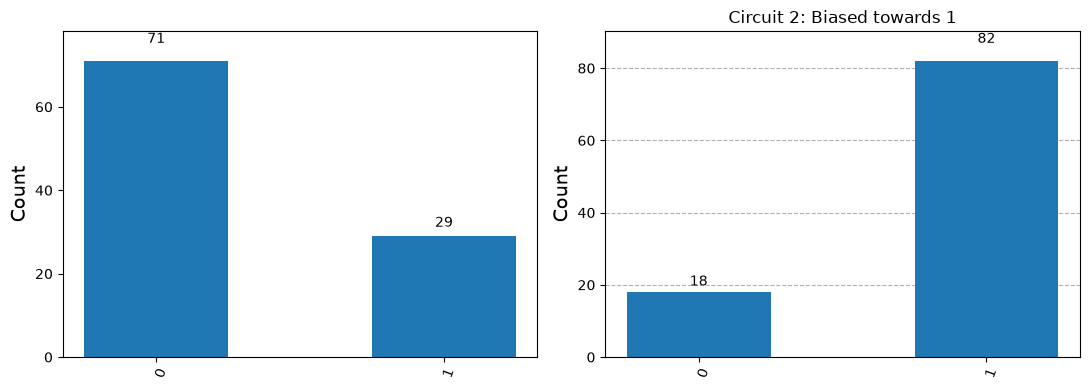

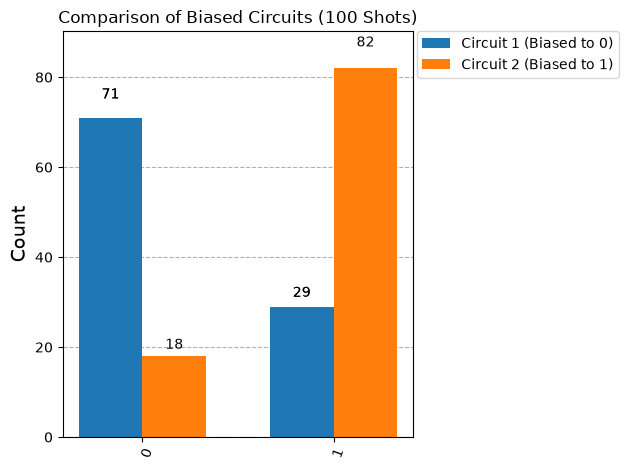

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_histogram(counts_zero, ax=axes[0], title="Circuit 1: Biased to 0 (Target ~75:25)")
plot_histogram(counts_one, ax=axes[1], title="Circuit 2: Biased to 1 (Target ~25:75)")
plt.tight_layout()
plt.show()

plot_histogram([counts_zero, counts_one], 
               legend=["Circuit 1 (Biased to 0)", "Circuit 2 (Biased to 1)"],
               title="Comparison of Biased Circuits (100 Shots)")
plt.show()

### Short Explanation of Results

- In Circuit 1, outcome `0` occurred 71 times and `1` occurred 29 times. This closely matches our theoretical 75:25 prediction.
- In Circuit 2, outcome `1` occurred 82 times and `0` occurred 18 times. This shows we successfully reversed the bias towards outcome 1.
- By changing the rotation angle $\theta$, we can control the exact degree of bias in the quantum coin.

### Challenge Question (Answer in Last Cell)

**Question:** How can quantum gates change the probability of obtaining 0 or 1 when a qubit is measured?

**Answer:**
A qubit state in superposition is written as $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$, where $\alpha$ and $\beta$ are probability amplitudes. According to Born's rule, when we measure the qubit, the probability of obtaining 0 is $|\alpha|^2$ and the probability of obtaining 1 is $|\beta|^2$ (where $|\alpha|^2 + |\beta|^2 = 1$).

Quantum gates act as rotation operations on the Bloch sphere. When a gate rotates the state vector closer to $|0\rangle$ (the north pole), it increases the amplitude $\alpha$, which increases the probability of measuring 0. When a gate rotates it closer to $|1\rangle$ (the south pole), it increases $\beta$, making outcome 1 more probable. An H gate places the vector right in the middle (equator), making $\alpha = \beta = 1/\sqrt{2}$ (50/50). Therefore, quantum gates change the measurement probabilities by rotating the state vector and modifying the amplitudes $\alpha$ and $\beta$ before measurement.